In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import csv
import numpy as np
import json
from tqdm import tqdm
import matplotlib.ticker as plticker


In [10]:
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 22}

plt.rcParams.update({'font.size': 22})

In [3]:
fp = "Data/pathway_appearences.csv"
df = pd.read_csv(fp)
print(df.head())
print(len(df))

   Pathway  Size  Chirality  Timestep  Not_Appear  Percent_Appear  \
0      720    51   0.470588        22           0        1.000000   
1     1059    67   0.686567         0          30        0.552239   
2      410    32   0.437500        18           0        1.000000   
3      680    92   0.565217         0          15        0.836957   
4      920    48   0.291667         0           1        0.979167   

   Max_Appearence_Timestep  Chirality_Max_Appearence  
0                       22                  0.550116  
1                       32                  0.586339  
2                       18                  0.548691  
3                       29                  0.580453  
4                       25                  0.555992  
154


In [4]:
#Find labels of each pathway
fp = "Data/pathway_names.json"
with open(fp) as f:
  pathway_names = json.load(f)

#Find overall labels (overview) and specific (sub-class) labels
pathway_overview_names_dict = {}
pathway_specific_names_dict = {}
for key in pathway_names["children"]:
  #key["name"]) -> the overview names of the pathway classes
  for key2 in key["children"]:
    #key2["name"] -> specifc names of pathway classes
    for key3 in key2["children"]:
      specific_name = key3["name"][:5]
      pathway_overview_names_dict[int(specific_name)] = key["name"]
      pathway_specific_names_dict[int(specific_name)] = key2["name"]

print(pathway_overview_names_dict)

{1100: 'Metabolism', 1110: 'Metabolism', 1120: 'Metabolism', 1200: 'Metabolism', 1210: 'Metabolism', 1212: 'Metabolism', 1230: 'Metabolism', 1220: 'Metabolism', 10: 'Metabolism', 20: 'Metabolism', 30: 'Metabolism', 40: 'Metabolism', 51: 'Metabolism', 52: 'Metabolism', 53: 'Metabolism', 500: 'Metabolism', 520: 'Metabolism', 620: 'Metabolism', 630: 'Metabolism', 640: 'Metabolism', 650: 'Metabolism', 660: 'Metabolism', 562: 'Metabolism', 190: 'Metabolism', 195: 'Metabolism', 196: 'Metabolism', 710: 'Metabolism', 720: 'Metabolism', 680: 'Metabolism', 910: 'Metabolism', 920: 'Metabolism', 61: 'Metabolism', 62: 'Metabolism', 71: 'Metabolism', 72: 'Metabolism', 73: 'Metabolism', 100: 'Metabolism', 120: 'Metabolism', 121: 'Metabolism', 140: 'Metabolism', 561: 'Metabolism', 564: 'Metabolism', 565: 'Metabolism', 600: 'Metabolism', 590: 'Metabolism', 591: 'Metabolism', 592: 'Metabolism', 1040: 'Metabolism', 230: 'Metabolism', 240: 'Metabolism', 250: 'Metabolism', 260: 'Metabolism', 270: 'Metaboli

In [5]:
#Set up metabolic dataframe containing data only from metabolic pathways
metabolic_df = pd.DataFrame()

for index, row in df.iterrows():
  try:
    name = pathway_overview_names_dict[row["Pathway"]]
  except:
    name = ""

  if name == "Metabolism":
    metabolic_df = metabolic_df.append(row)

print(metabolic_df.head())
print(len(metabolic_df))

   Pathway  Size  Chirality  Timestep  Not_Appear  Percent_Appear  \
0    720.0  51.0   0.470588      22.0         0.0        1.000000   
1   1059.0  67.0   0.686567       0.0        30.0        0.552239   
2    410.0  32.0   0.437500      18.0         0.0        1.000000   
3    680.0  92.0   0.565217       0.0        15.0        0.836957   
4    920.0  48.0   0.291667       0.0         1.0        0.979167   

   Max_Appearence_Timestep  Chirality_Max_Appearence  
0                     22.0                  0.550116  
1                     32.0                  0.586339  
2                     18.0                  0.548691  
3                     29.0                  0.580453  
4                     25.0                  0.555992  
151


In [6]:
#Hardcoding metabolic pathway subgroup names & colors

metabolism_groups = {"Carbohydrate Metabolism": [10,20,30,40,51,52,53,500,520,620,630,640,650,660,562],
                     "Glycan Biosynthesis": [510,513,512,515,514,532,534,533,531,563,601,603,604,540,542,541,550,511,571,572],
                     "Terpenoids and Polyketides": [900,902,909,904,906,905,981,908,903,281,1052,522,1051,1059,1056,1057,253,523,1054,1053,1055],
                     "Lipid Metabolism": [61,62,71,73,100,120,121,140,561,564,565,600,590,591,592,1040],
                     "Secondary Metabolite Biosynthesis": [940,945,941,944,942,943,901,403,950,960,1058,232,965,966,402,311,332,261,331,521,524,525,401,404,405,333,254,999,998,997],
                     "Nucleotide Metabolism": [230,240],
                     "Amino Acid Metabolism": [250,260,270,280,290,300,310,220,330,340,350,360,380,400],
                     "Metabolism of Other Amino Acids": [410,430,440,450,460,470,480],
                     "Cofactors and Vitamins": [730,740,750,760,770,780,785,790,670,830,860,130],
                     "Energy Metabolism": [190,195,196,710,720,680,910,920],
                     "Xenobiotics": [362,627,364,625,361,623,622,633,642,643,791,930,363,621,626,624,365,984,980,982,983]}

colors = {"Carbohydrate Metabolism": "#aa0f35", 
          "Glycan Biosynthesis": "#487c7c", 
          "Terpenoids and Polyketides": "#009ecb", 
          "Lipid Metabolism": "#abdbfc", 
          "Secondary Metabolite Biosynthesis": "#430057", 
          "Nucleotide Metabolism": "#a0a75c", 
          "Amino Acid Metabolism": "#603734",
          "Metabolism of Other Amino Acids": "#d97e43", 
          "Cofactors and Vitamins": "#313a61", 
          "Energy Metabolism": "#fdc799",
          "Xenobiotics": "#f5c500"}

pathway_group_keys = {"Carbohydrate Metabolism": 1, 
          "Glycan Biosynthesis": 2, 
          "Terpenoids and Polyketides": 3, 
          "Lipid Metabolism": 4, 
          "Secondary Metabolite Biosynthesis": 5, 
          "Nucleotide Metabolism": 6, 
          "Amino Acid Metabolism": 7,
          "Metabolism of Other Amino Acids": 8, 
          "Cofactors and Vitamins": 9, 
          "Energy Metabolism": 10,
          "Xenobiotics": 11}

color_list = ["#aa0f35", 
          "#487c7c", 
          "#009ecb", 
          "#abdbfc", 
          "#430057", 
          "#a0a75c", 
          "#603734",
          "#d97e43", 
          "#fdc799",
          "#313a61", 
          "#f5c500"]

def set_box_color(bp, color):
  plt.setp(bp['boxes'], color=color)
  plt.setp(bp['whiskers'], color=color)
  plt.setp(bp['caps'], color=color)
  plt.setp(bp['medians'], color=color)

In [7]:
#Assign colors to all metabolic pathways
pathway_groups = {}
pathway_group_colors = {}
pathway_groups_list = []
pathway_key_list = []
pathway_colors = []

for _, row in metabolic_df.iterrows():
  found_group = 0
  for group, pathways in metabolism_groups.items():
    if int(row["Pathway"]) in pathways:
      pathway_groups[int(row["Pathway"])] = group
      pathway_group_colors[int(row["Pathway"])] = colors[group]
      pathway_groups_list.append(group)
      pathway_key_list.append(pathway_group_keys[group])
      pathway_colors.append(row["Pathway"])
      found_group = 1
  if not found_group:
    pathway_groups_list.append(np.NaN)
    pathway_key_list.append(np.NaN)
    pathway_colors.append(np.NaN)

print(pathway_groups)
print(pathway_group_colors)
metabolic_df["Group"] = pathway_groups_list
metabolic_df["Group Key"] = pathway_key_list
metabolic_df["Color"] = pathway_colors

#Setup for box & whisker plot - needs a 2d array of chiralities
chiralities = []
for group in colors.keys():
  chiralities.append(df[df['Pathway'].isin(metabolism_groups[group])]["Chirality"].tolist())

print(chiralities)

{720: 'Energy Metabolism', 1059: 'Terpenoids and Polyketides', 410: 'Metabolism of Other Amino Acids', 680: 'Energy Metabolism', 920: 'Energy Metabolism', 600: 'Lipid Metabolism', 550: 'Glycan Biosynthesis', 311: 'Secondary Metabolite Biosynthesis', 310: 'Amino Acid Metabolism', 10: 'Carbohydrate Metabolism', 254: 'Secondary Metabolite Biosynthesis', 250: 'Amino Acid Metabolism', 253: 'Terpenoids and Polyketides', 540: 'Glycan Biosynthesis', 910: 'Energy Metabolism', 140: 'Lipid Metabolism', 750: 'Cofactors and Vitamins', 999: 'Secondary Metabolite Biosynthesis', 998: 'Secondary Metabolite Biosynthesis', 300: 'Amino Acid Metabolism', 20: 'Carbohydrate Metabolism', 380: 'Amino Acid Metabolism', 220: 'Amino Acid Metabolism', 904: 'Terpenoids and Polyketides', 905: 'Terpenoids and Polyketides', 906: 'Terpenoids and Polyketides', 900: 'Terpenoids and Polyketides', 901: 'Secondary Metabolite Biosynthesis', 902: 'Terpenoids and Polyketides', 903: 'Terpenoids and Polyketides', 908: 'Terpenoid

In [8]:
print(metabolic_df)

     Pathway  Size  Chirality  Timestep  Not_Appear  Percent_Appear  \
0      720.0  51.0   0.470588      22.0         0.0        1.000000   
1     1059.0  67.0   0.686567       0.0        30.0        0.552239   
2      410.0  32.0   0.437500      18.0         0.0        1.000000   
3      680.0  92.0   0.565217       0.0        15.0        0.836957   
4      920.0  48.0   0.291667       0.0         1.0        0.979167   
..       ...   ...        ...       ...         ...             ...   
149    561.0  40.0   0.700000      29.0         0.0        1.000000   
150    333.0  18.0   0.222222       0.0         5.0        0.722222   
151    240.0  70.0   0.657143       0.0         1.0        0.985714   
152    332.0  32.0   0.812500       0.0         9.0        0.718750   
153    480.0  42.0   0.761905       0.0         3.0        0.928571   

     Max_Appearence_Timestep  Chirality_Max_Appearence  \
0                       22.0                  0.550116   
1                       32.0   

(-0.25, 1.3)

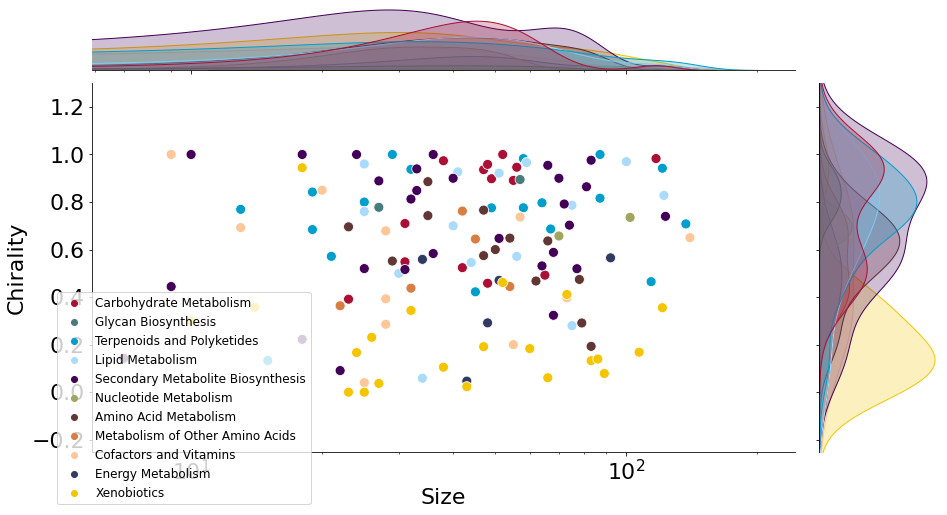

In [68]:
# Scatter plot for each pathway: x-axis=size, y-axis=eq(C), color=pathway color

#fig, ax = plt.subplots(figsize=(8,8))

metabolic_df.sort_values(by="Group Key", inplace=True)

g = sns.jointplot(data=metabolic_df, x="Size", y="Chirality", 
                  hue="Group", s=100, palette=color_list, dropna=True, kind="scatter")

g.figure.set_size_inches((16, 8))

#g.ax_joint.legend(bbox_to_anchor=(0.32,0.45), prop={"size":12})

g.ax_joint.set_xscale("log")
g.ax_joint.set_ylim(-.25, 1.3)

/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:39: UserWarning: FixedFormatter should only be used together with FixedLocator


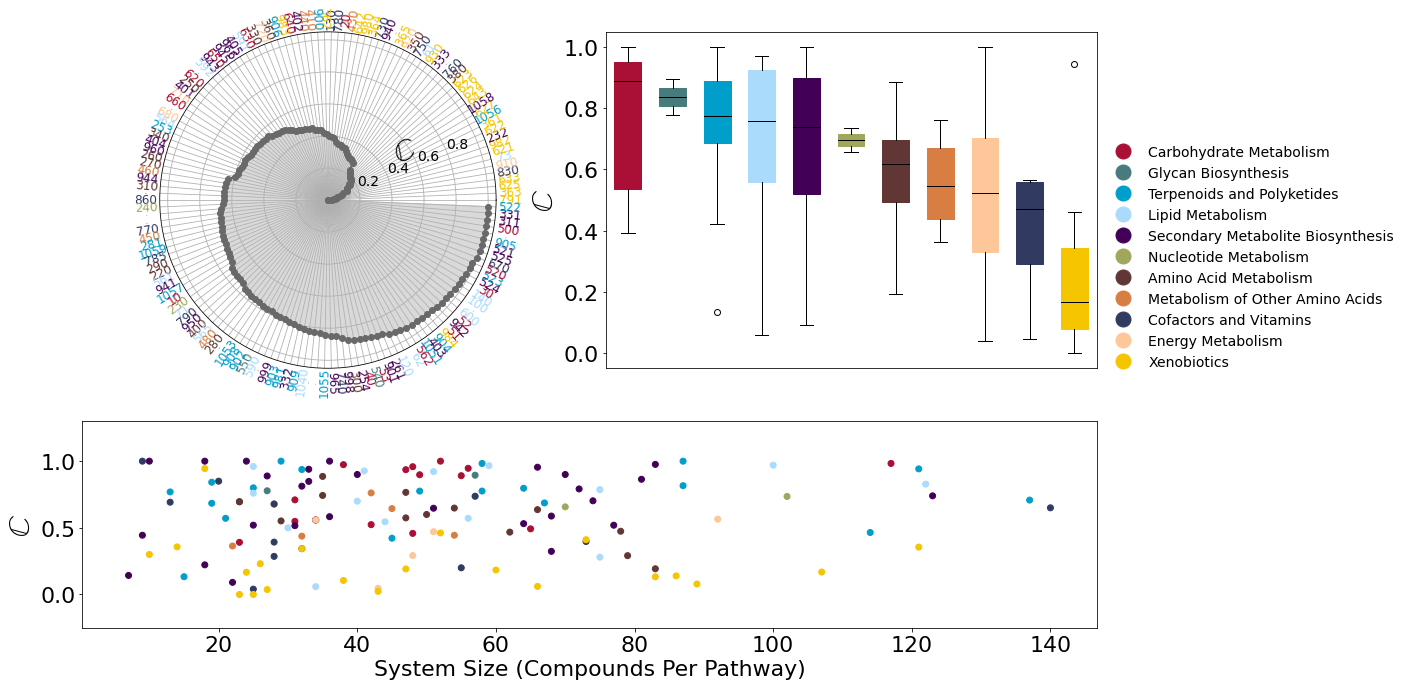

In [19]:
from matplotlib.gridspec import GridSpec
gs = GridSpec(10,2)

#Sort dataframe by a specific value
df = df.sort_values(by=["Chirality"])

#Label with pathway number
labels = df['Pathway'].tolist()

#Define each angle for plotting
angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False)
stats = df['Chirality'].tolist()
#stats.sort()
# stats = np.concatenate((stats, [stats[0]]))
# angles = np.concatenate((angles,[angles[0]]))

fig = plt.figure(figsize=(20,10))
ax = fig.add_subplot(gs[0:6,0], polar=True)
ax.plot(angles, stats, 'o-', linewidth=2, color="dimgrey")
ax.fill(angles, stats, alpha=0.25, color="dimgrey")
ax.set_thetagrids(angles * 180/np.pi, labels,)

#Make all angles rotated according to placement on the image
#plt.gca.canvas.draw()
angles[np.cos(angles) < 0] = angles[np.cos(angles) < 0] + np.pi
angles = np.rad2deg(angles)
for label, angle in zip(ax.get_xticklabels(), angles):
  x,y = label.get_position()
  try:
    lab = ax.text(x, y, label.get_text(), transform=label.get_transform(), 
                ha=label.get_ha(), va=label.get_va(), color=str(pathway_group_colors[int(label.get_text())]),
                fontsize=12)
  except:
    lab = ax.text(x, y, label.get_text(), transform=label.get_transform(), 
                ha=label.get_ha(), va=label.get_va(), color='k', fontsize=1)
  lab.set_rotation(angle)
  labels.append(lab)
ax.set_xticklabels([])
ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", ""], fontsize=14)

#label chiral percentage 
label_pos = ax.get_rlabel_position()
ax.text(np.radians(label_pos+10), ax.get_rmax()/2. + 0.05, "$\mathbb{C}$",
        rotation=label_pos+4, ha='center', va='center', fontsize=30, weight="bold")


ax2 = fig.add_subplot(gs[0:6,1])

sub_df = df[df["Pathway"].isin(metabolism_groups["Carbohydrate Metabolism"])]

c = colors["Carbohydrate Metabolism"]

bplot = ax2.boxplot(chiralities, patch_artist=True, positions=np.array(range(len(chiralities)))*1.0-0.4, widths=0.6, medianprops=dict(color="black")) # color=colors["Carbohydrate Metabolism"])

for patch, c in zip(bplot["boxes"], color_list):
  #patch.set_facecolor(color)
  patch.set_color(c)
  #patch.set_edgecolor(color)
# for item in ['boxes', 'whiskers', 'fliers', 'medians', 'caps']:
#         plt.setp(boxes[item], color=color_list[i])
# plt.setp(boxes["boxes"], facecolor=color_list[i])
# plt.setp(boxes["fliers"], markeredgecolor=color_list[i])

#plt.legend(bplot["boxes"], colors.keys(), bbox_to_anchor=(1.02,1.02), prop={"size": 14})
ax2.set_ylabel("$\mathbb{C}$", fontsize=30)

#Remove xticks
#frame1 = plt.gca()
ax2.xaxis.set_ticks([])

#legend of label colors
markers = [plt.Line2D([0,0],[0,0],color=color, marker='o', linestyle='', markersize=15) for color in colors.values()]
ax2.legend(markers, colors.keys(), bbox_to_anchor=(1, 0.7), loc="upper left", numpoints=1, frameon=False, prop={"size":14})
ax.grid(True)

### Pathway size by chirality
ax3 = fig.add_subplot(gs[6:,:])

metabolic_df = metabolic_df.dropna()

metabolic_df.sort_values(by="Group Key", inplace=True)

ax3.scatter(metabolic_df['Size'], metabolic_df['Chirality'], c=metabolic_df['Group'].map(colors))

ax3.set_ylabel("$\mathbb{C}$", fontsize=30)
ax3.set_xlabel("System Size (Compounds Per Pathway)")

loc = plticker.MultipleLocator(base=20.0) # this locator puts ticks at regular intervals
ax3.xaxis.set_major_locator(loc)

#ax3.set_xscale("log")
ax3.set_ylim(-.25, 1.3)

plt.tight_layout()

plt.savefig("fig6.svg", format="svg")